# 01 Data Understanding
Load the Kaggle dataset and audit shape, types, missingness, cardinality, duplicates, suspicious values, and outliers.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import CATEGORICAL_COLUMNS, NUMERIC_COLUMNS, TARGET
from src.data_loader import load_raw_data
from src.data_validation import audit_dataframe

data = load_raw_data(PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv")
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
audit = audit_dataframe(data)
print("Shape:", audit["shape"])
print("Columns:", audit["columns"])
print("Numeric columns:", audit["numeric_columns"])
print("Categorical columns:", audit["categorical_columns"])
print("Duplicate rows:", audit["duplicate_rows"])
print("Constant columns:", audit["constant_columns"])
print("Blank TotalCharges after safe conversion:", audit["blank_total_charges"])
audit

Shape: (7043, 21)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
Categorical columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Duplicate rows: 0
Constant columns: []
Blank TotalCharges after safe conversion: 11


{'shape': (7043, 21),
 'columns': ['customerID',
  'gender',
  'SeniorCitizen',
  'Partner',
  'Dependents',
  'tenure',
  'PhoneService',
  'MultipleLines',
  'InternetService',
  'OnlineSecurity',
  'OnlineBackup',
  'DeviceProtection',
  'TechSupport',
  'StreamingTV',
  'StreamingMovies',
  'Contract',
  'PaperlessBilling',
  'PaymentMethod',
  'MonthlyCharges',
  'TotalCharges',
  'Churn'],
 'dtypes': {'customerID': 'object',
  'gender': 'object',
  'SeniorCitizen': 'int64',
  'Partner': 'object',
  'Dependents': 'object',
  'tenure': 'int64',
  'PhoneService': 'object',
  'MultipleLines': 'object',
  'InternetService': 'object',
  'OnlineSecurity': 'object',
  'OnlineBackup': 'object',
  'DeviceProtection': 'object',
  'TechSupport': 'object',
  'StreamingTV': 'object',
  'StreamingMovies': 'object',
  'Contract': 'object',
  'PaperlessBilling': 'object',
  'PaymentMethod': 'object',
  'MonthlyCharges': 'float64',
  'TotalCharges': 'float64',
  'Churn': 'Int64'},
 'numeric_column

In [3]:
import pandas as pd

data_dictionary = pd.DataFrame({
    "Feature": data.columns,
    "Type": data.dtypes.astype(str).values,
    "Meaning": [
        "Customer identifier", "Customer gender", "Senior citizen flag", "Partner status", "Dependents status",
        "Months with company", "Phone service", "Multiple lines", "Internet service", "Online security",
        "Online backup", "Device protection", "Technical support", "Streaming TV", "Streaming movies",
        "Contract term", "Paperless billing", "Payment method", "Monthly charge", "Cumulative charge", "Churn target"
    ],
    "Missing": data.isna().sum().values,
    "Cardinality": data.nunique(dropna=False).values,
    "Treatment": [
        "Retain for reporting; exclude from predictors", "Categorical encoding", "Binary numeric", "Categorical encoding", "Categorical encoding",
        "Numeric; inspect distribution", "Categorical encoding", "Categorical encoding", "Categorical encoding", "Categorical encoding",
        "Categorical encoding", "Categorical encoding", "Categorical encoding", "Categorical encoding", "Categorical encoding",
        "Categorical encoding", "Categorical encoding", "Categorical encoding", "Numeric", "Coerce blanks to missing then impute", "Map Yes/No to 1/0"
    ]
})
data_dictionary

,Feature,Type,Meaning,Missing,Cardinality,Treatment
0,customerID,object,Customer identifier,0,7043,Retain for reporting; exclude from predictors
1,gender,object,Customer gender,0,2,Categorical encoding
2,SeniorCitizen,int64,Senior citizen flag,0,2,Binary numeric
3,Partner,object,Partner status,0,2,Categorical encoding
4,Dependents,object,Dependents status,0,2,Categorical encoding
5,tenure,int64,Months with company,0,73,Numeric; inspect distribution
6,PhoneService,object,Phone service,0,2,Categorical encoding
7,MultipleLines,object,Multiple lines,0,3,Categorical encoding
8,InternetService,object,Internet service,0,3,Categorical encoding
9,OnlineSecurity,object,Online security,0,3,Categorical encoding


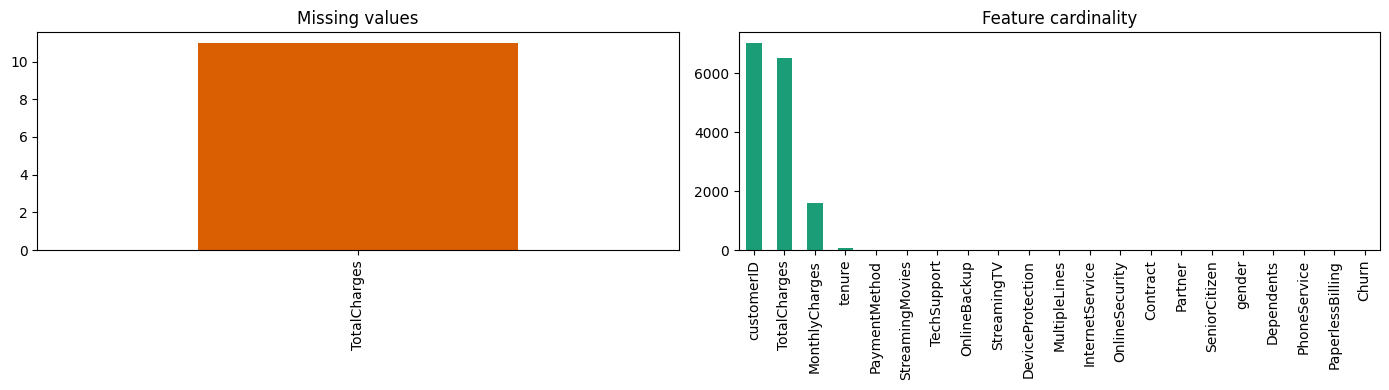

,count
negative_tenure,0
negative_monthly_charges,0
negative_total_charges,0
invalid_churn_values,0
duplicate_customer_ids,0


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
missing = data.isna().sum().sort_values(ascending=False)
missing[missing > 0].plot.bar(ax=axes[0], color="#d95f02", title="Missing values")
cardinality = data.nunique().sort_values(ascending=False)
cardinality.plot.bar(ax=axes[1], color="#1b9e77", title="Feature cardinality")
plt.tight_layout()
plt.show()

suspicious = {
    "negative_tenure": int((data["tenure"] < 0).sum()),
    "negative_monthly_charges": int((data["MonthlyCharges"] < 0).sum()),
    "negative_total_charges": int((data["TotalCharges"] < 0).sum()),
    "invalid_churn_values": int((~data["Churn"].isin([0, 1])).sum()),
    "duplicate_customer_ids": int(data["customerID"].duplicated().sum()),
}
pd.Series(suspicious, name="count").to_frame()

## Outcome and usefulness

### Outcome
- The notebook establishes the structural baseline of the Kaggle Telco Customer Churn data: row count, column names, data types, numeric and categorical variables, target distribution, missingness, cardinality, duplicates, constants, suspicious values, and outlier counts.
- `TotalCharges` is safely converted to numeric. The source data contains 11 blank values, which become missing values instead of being silently treated as zero.
- `customerID` is unique identifier information, not customer behavior. It is retained for reporting and customer-level scoring but excluded from model predictors.
- The audit checks the main validity risks: negative tenure or charges, invalid target values, duplicate customer identifiers, duplicate rows, constant columns, and unusual cardinalities. Any issue found here must be resolved or documented before modeling.
- The data dictionary records the meaning and treatment of every source feature, creating a traceable contract between the raw dataset and later preprocessing.

### Why this is useful
- It prevents silent data-quality errors from becoming model behavior.
- It defines which columns are numeric, categorical, identifiers, targets, or missing-value problems before any encoding or feature engineering occurs.
- It protects against identifier leakage by explicitly excluding `customerID`.
- It tells the preprocessing stage how to treat `TotalCharges` and other missing values.
- It gives later statistical tests and model results a reproducible sample-size and data-quality context.
- It creates an auditable starting point for the entire project. The next stage can therefore focus on customer behavior rather than wondering whether the input table was interpreted correctly.

### Modeling hand-off
Use the cleaned target and validated predictors for EDA. Keep the raw dataset unchanged, preserve the audit output, and perform all imputation or learned transformations inside the training workflow.